# T18 策略参数比较（仅探索，不得作为策略输入）

> **状态：探索性结论。** 本 notebook 只在回放器上比较参数，不调用真实评估器，也不把任何本地实测 R 带进第一批。上一版 notebook 依据 6,568 次本地 `solver.exe` 调用给出的「§6 结构先验」和「§9 T12 可直接采用该排序」**均已撤回**：决策 19 规定第 1 次调用前只能使用 2048 条训练行，T03（能否用本地评估器结果调参）尚未答复。

负责：胡馨澜（D）。证据：`analysis/replay/results/20261109/`；协议与限制见 `analysis/replay/README.md`。

## 1. 回放协议

- 20 次调用 × 每批至多 50 点（在线额度：1000 点）。
- 候选池 1600 行，已知数据 448 行。
- 种子 0–4，同时控制池划分、策略随机性和模型种子。
- 两种真值：`table`（留出行查表）与 `semi-synthetic`（在全部 2048 行上拟合的 histgb）。
- 对比：利用比例 0.0 / 0.5 / 1.0；信赖域半径 1.0（最强代理另加 0.5）；代理 `ridge2`、`histgb`。
- 计分口径：曲线只统计**实际提交**的点；已知 448 行的最优值（training incumbent）单独标注为参考线，不进入曲线。
- 半径规则（table 真值）：只提交半径内的候选行；不足 50 个时批次变小，不再静默越界补批；每次调用记录 eligible / submitted / 实际距离比（见 `runs.jsonl` 的 `call_log`）。

候选池比额度大是刻意的：池更小时任何策略都会看完整池，曲线就没有信息。

In [1]:
import json
from pathlib import Path

result = json.loads(Path('results/20261109/results.json').read_text(encoding='utf-8'))
rows = result['runs']
ref = result['training_incumbent_reference']
print('training incumbent (reference, never submitted):',
      '; '.join(f"{k} {v['mean']:.3f}" for k, v in sorted(ref.items())))
print(f"{'truth':14s} {'surrogate':8s} {'exploit':>7s} {'radius':>6s} {'best@1':>8s} {'calls':>6s} {'final':>8s} {'std':>6s} {'pts/call':>9s} {'maxdist':>8s}")
for r in rows:
    pts = '-' if r['submitted_per_call_mean'] is None else f"{r['submitted_per_call_mean']:.1f}"
    md = '-' if r['max_distance_ratio_observed'] is None else f"{r['max_distance_ratio_observed']:.2f}"
    print(f"{r['truth']:14s} {r['surrogate']:8s} {r['exploit']:7.1f} {r['radius']:6.1f} "
          f"{r['first_call_mean']:8.3f} {r['calls_to_final_median']:6.0f} "
          f"{r['final_mean']:8.3f} {r['final_std']:6.3f} {pts:>9s} {md:>8s}")


training incumbent (reference, never submitted): semi-synthetic 128.371; table 117.437
truth          surrogate exploit radius   best@1  calls    final    std  pts/call  maxdist
semi-synthetic ridge2       0.5    1.0  128.183      1  128.175  0.000         -        -
semi-synthetic histgb       0.5    1.0  128.263      1  128.175  0.000         -        -
semi-synthetic histgb       1.0    1.0  128.263      1  128.175  0.000         -        -
semi-synthetic histgb       0.5    0.5  128.263      1  128.175  0.000         -        -
semi-synthetic ridge2       1.0    1.0  128.540      1  128.175  0.000         -        -
semi-synthetic ridge2       0.0    1.0  128.563      1  128.175  0.000         -        -
semi-synthetic histgb       0.0    1.0  128.563      1  128.175  0.000         -        -
table          ridge2       1.0    1.0  117.350      1  117.350  1.957      27.8     1.00
table          histgb       0.5    1.0  117.350      1  117.350  1.957      27.3     1.00
table       

## 2. 结论

- **计分口径已修正**：曲线只统计实际提交点的最优值；448 条已知行的 incumbent 仅作参考线（table 117.437，semi-synthetic 128.371，种子均值）。初版把已知行混入曲线，曾让 table 真值下所有设置看似并列 115.765 —— 那是已知行里的 p01969，并非策略提交得到。
- `semi-synthetic` 一支仍无区分力：所有设置中位 1 次调用即达真值最小 128.175，首批成绩差异仅 128.183–128.563。它是健全性检查，不是排序证据。
- `table` 真值只在第 1 批区分利用比例：利用比例 ≥ 0.5 在第 1 批就拿到各种子的池最小值（首批 117.350 / 117.507；均值终值 117.350 ± 1.957；种子 0/3/4 为 115.765；种子 1/2 的 p01969 在已知行中，池最小为 120.119 / 119.334）。纯探索首批只有 126.937 ± 2.833，中位 5 次调用才追上。第 1 批之后该真值无法再排序：每个利用比 ≥ 0.5 的运行都会耗尽半径内候选，终值等于池最小值。
- **本回放无法区分半径 0.5 与 1.0**：`table` 真值下半径只是在固定池里筛行，两组差别在「能提交多少点」而非「往哪里看」。种子 0、`histgb`、利用比 0.5：半径 0.5 的 eligible 为 8 → 2 → 0，整轮只提交 10 点；半径 1.0 为 761 → 623 → … → 3 → 0，整轮提交 501 点（第 11 次调用池子耗尽）。因此 133.697 与 117.350 之差反映的是池供给量，不是半径效应。`semi-synthetic` 一支用的是真实 `bayes-pool`（每次调用在半径内抽 6000 个新候选，不会缺货），两个半径结果完全相同（首批 128.263，终值 128.175）。
- **代理模型无法区分**（`ridge2` 与 `histgb` 结果相同），模型选择仍由 T12 在 `sdm evaluate` 上决定。

### 逐次最优值曲线（两种真值，种子均值）

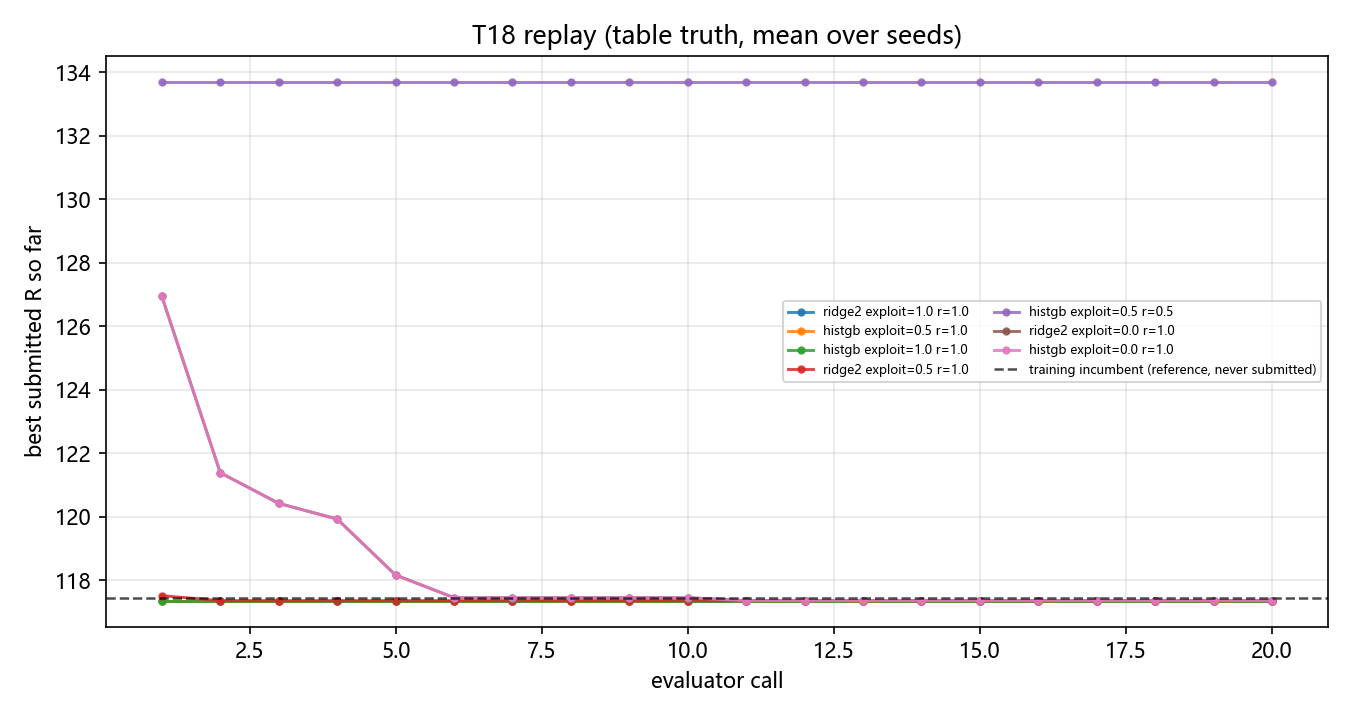

In [5]:
from IPython.display import Image, display
display(Image(filename='results/20261109/figures/replay_table.png'))

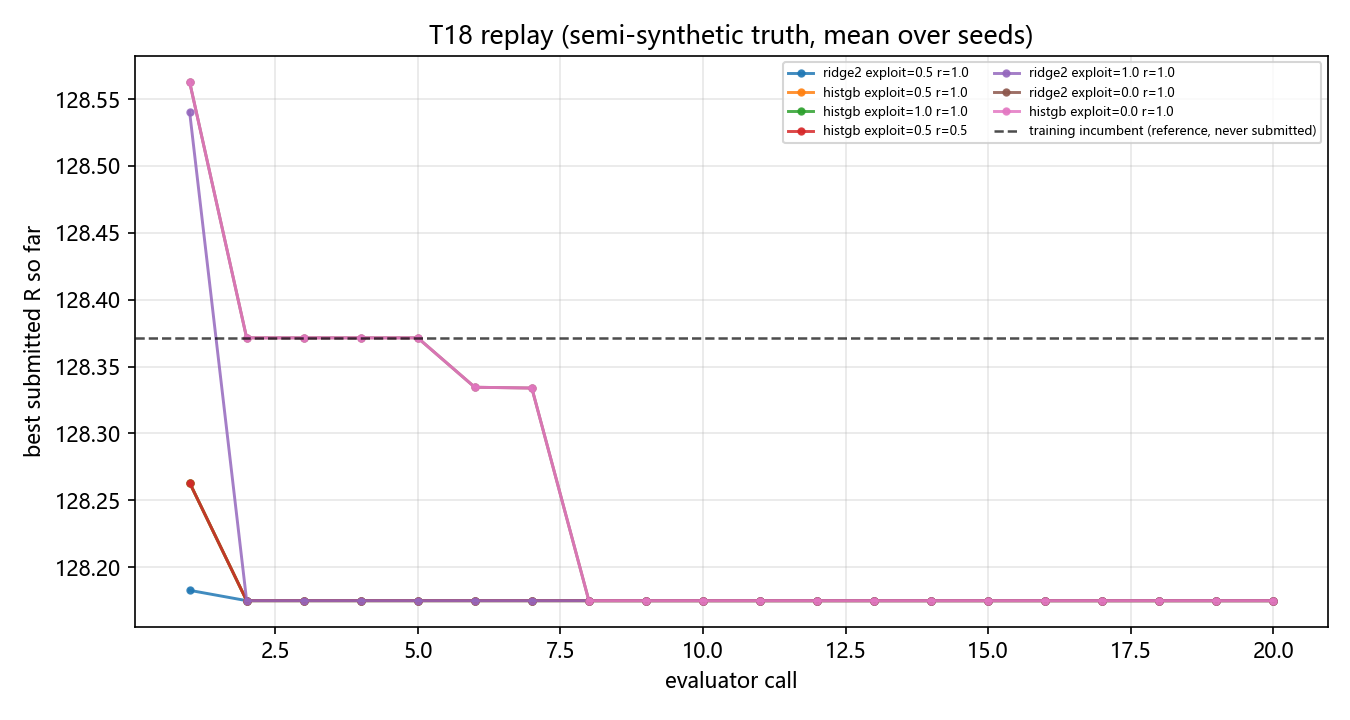

In [6]:
from IPython.display import Image, display
display(Image(filename='results/20261109/figures/replay_semi_synthetic.png'))

### 达到各自最好值所需调用次数

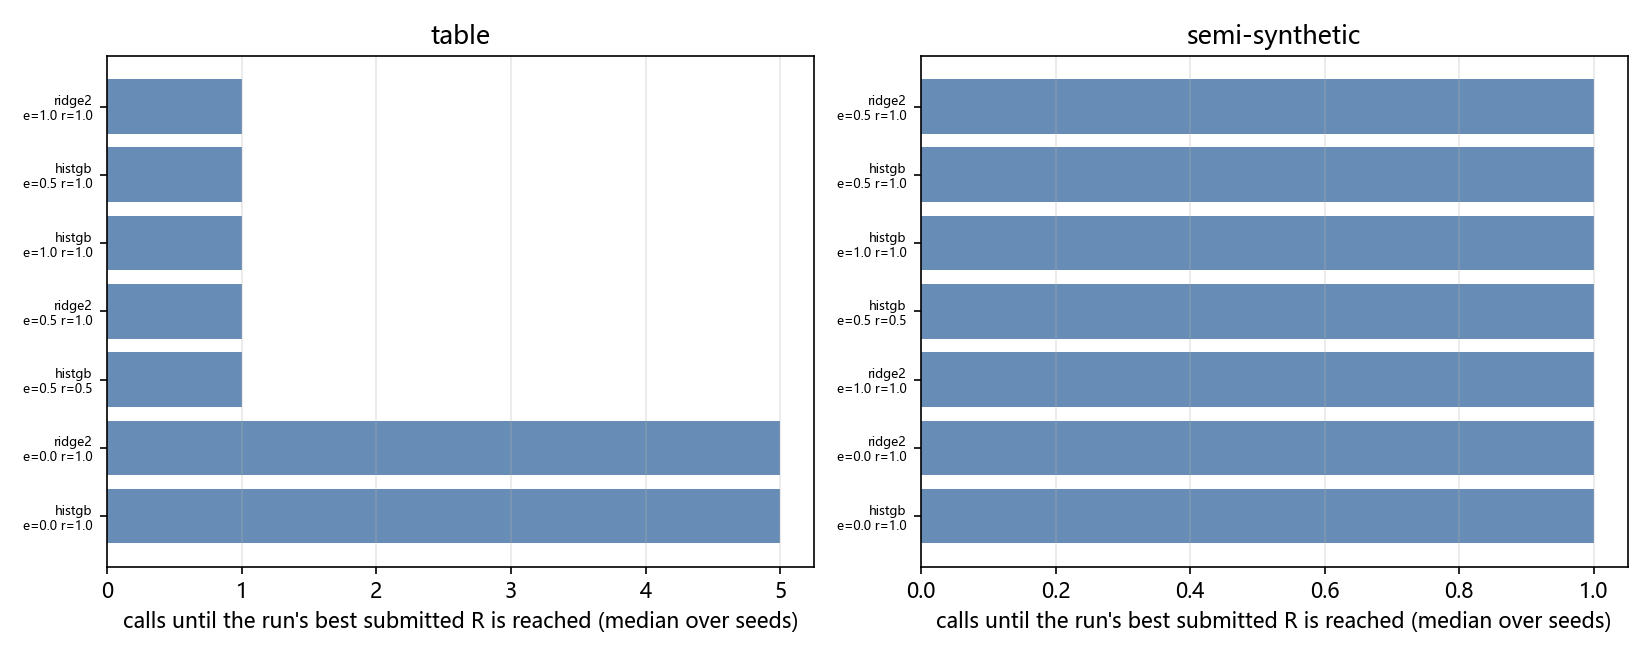

In [8]:
from IPython.display import Image, display
display(Image(filename='results/20261109/figures/calls_to_final_best.png'))

## 3. 推荐配置（仅回放证据，是默认值而非实测收益）

| 参数 | 推荐值 | 依据 |
|---|---|---|
| 利用比例 | 0.5 | 两种真值下与 1.0 并列；0.5 保留一半探索。属判断，不是实测增益 |
| 信赖域半径 | 1.0（max distance ratio） | 判断性默认：本回放无法区分 0.5 与 1.0（半合成真值下完全相同；table 一支受固定池供给限制） |
| 每批组成 | 25 利用 + 25 探索，不重复 | 决策 19 / T15 |
| 代理模型 | 由 T12 决定 | 本回放无法区分模型 |

配置：`experiments/online-policy-wide.toml`（推荐）与 `experiments/online-policy-narrow.toml`（半径对比臂）。利用比例目前不是 `main` 上任何提议插件（T15 进行中）的参数，T15 落地时补上。

## 4. 搜索历史（本地真实评估，不作为策略依据）

| 阶段（phase 前缀） | 次数 | 最好 R |
|---|---|---|
| 筛查（`screen`、`vertex`） | 387 | 120.299 |
| `v2`–`v4` 格点与一维扫描 | 181 | 106.522 |
| `v5` 半盲支持集 | 1,056 | 105.940 |
| `vE0` 探针 | 11 | 117.802 |
| `vE1` 三栋楼坐标轴 | 1,377 | 131.370 |
| `vE2` 结构化支持集 | 806 | 105.118 |
| `vE3` 地形与格点 | 1,994 | 105.022 |
| `vE4` 一维细扫 | 535 | 104.852 |
| `vE5` 量化探针 | 221 | 104.852 |

为什么只是历史：样本量极不均衡（11–1,994）且阶段顺序相接，后一阶段从前一阶段的结论出发；脚本未固定全部随机源、批次由人工切分，无法逐位复现；最好点（R = 104.851733，eval_id 6335）是本地实测，只能说明响应面存在这种形状的低点，不能当作第一批的先验。

## 5. 复现与限制

```bash
uv run python analysis/replay/study.py --seeds 5 --out analysis/replay/results/20261109
```

全程不调用评估器，单机约 15 分钟，池划分与每个策略都设了种子，可逐位复现；`--from-runs` 可只重算聚合而不重新拟合。

- `table` 真值只能选表内行，其最优是单行；真实响应面是连续的，收敛差异只能当作序数比较。
- `semi-synthetic` 真值在策略可见的同一批 2048 行上拟合，比真实评估器容易，且在本设计下没有区分力（所有设置 1 次调用内到达真值最小）。区分证据全部来自 table 真值；要做出更有区分力的回放，需要能在 20 次内持续改善已知行的真值（更冷的起步，或带距离漂移的连续真值）；这是 T17 的设计问题，不是 T18 的结论。
- table 池在已知数据附近的候选有限：半径 1.0 提交约 550 点后半径内候选即耗尽，平均每批约 27 点而非 50。真实策略在连续空间提议、无此上限；半径对比因此夸大了窄半径的代价幅度，但不改变方向。
- 本回放不检验运行器、日志、去重、额度（T06–T09），也不检验跨机器确定性（T09）。